# Explainable Fake Review Detection System using Machine Learning and SHAP Analysis

## 1. Import Libraries & Setup

In [1]:
# import all the libraries needed
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('punkt')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV
import shap

# Consistent colour palette used throughout the notebook
CLASS_COLORS = {
    'AI generated':  '#3498db',
    'deceptive':     '#e74c3c',
    'truthful':      '#2ecc71'
}
CLASS_ORDER  = ['AI generated', 'deceptive', 'truthful']
CLASS_LABELS = [ 'AI Generated', 'Human Fake', 'Genuine']

# Extra colours for Amazon comparison
DOMAIN_COLORS = {
    'Hotel Genuine':  '#2ecc71',
    'Amazon Genuine': '#8e44ad'
}

print('Libraries loaded successfully.')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Libraries loaded successfully.


## 2. Load Main Hotel Dataset

In [2]:
# read the hotel data
df = pd.read_csv('deceptive-opinion-augmented.csv')
print(f'Main dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Main dataset shape: (2400, 5)
Columns: ['label', 'hotel', 'polarity', 'source', 'text']


,label,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...


In [3]:
# check class, polarity and source counts
print('Class distribution (main 3-class dataset):')
print(df['label'].value_counts())
print('\nPolarity distribution:')
print(df['polarity'].value_counts())
print('\nSource distribution:')
print(df['source'].value_counts())

Class distribution (main 3-class dataset):
label
truthful        800
deceptive       800
AI generated    800
Name: count, dtype: int64

Polarity distribution:
polarity
positive    1200
negative    1200
Name: count, dtype: int64

Source distribution:
source
MTurk          800
AI             800
TripAdvisor    400
Web            400
Name: count, dtype: int64


## 3. Exploratory Data Analysis of Hotel Dataset

### 3.1 Class Balance

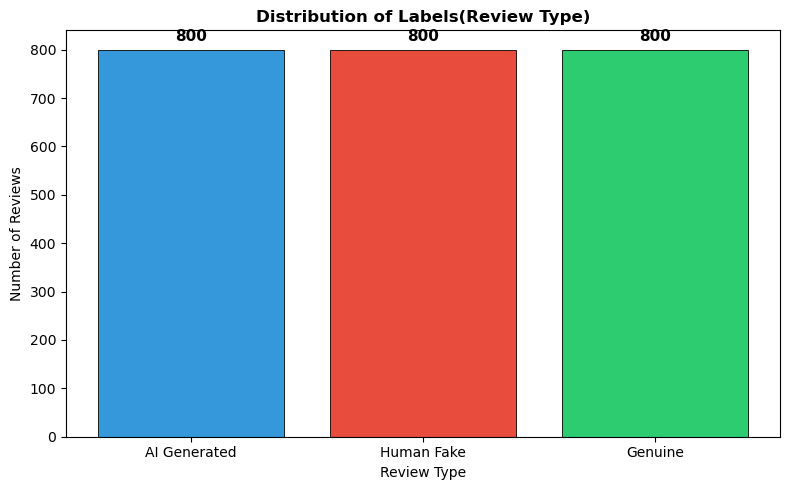

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
counts = df['label'].value_counts().reindex(CLASS_ORDER).fillna(0)
bars = ax.bar(CLASS_LABELS, counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('Distribution of Labels(Review Type)', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Review Type')

# show the count on top of each bar
for bar in bars:
    height = bar.get_height()
    val_str = f'{int(height)}' if not np.isnan(height) else '0'
    ax.annotate(val_str,
                xy=(bar.get_x() + bar.get_width()/2, height if not np.isnan(height) else 0),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### 3.2 Character Length by Class

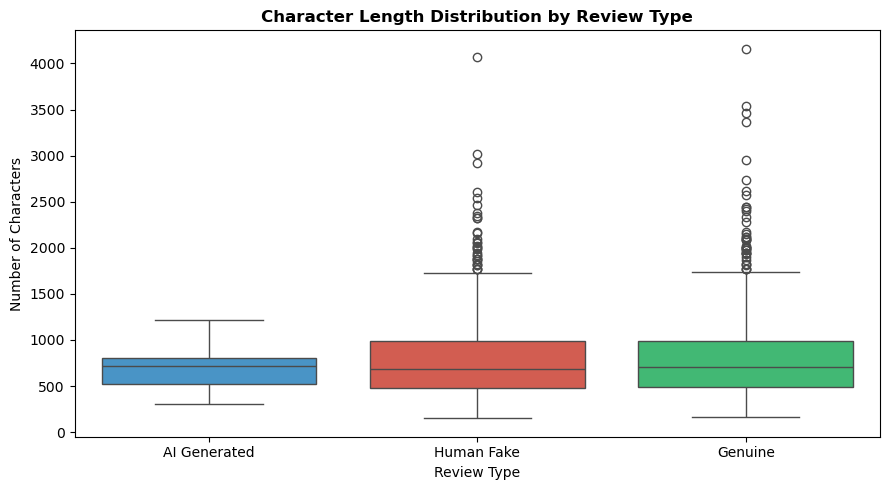

In [5]:
# length of each review in characters
df['char_length'] = df['text'].str.len()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='label', y='char_length',
            order=CLASS_ORDER, palette=CLASS_COLORS, ax=ax)

ax.set_xticklabels(CLASS_LABELS)
ax.set_title('Character Length Distribution by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Characters')

plt.tight_layout()
plt.show()

### 3.3 Word Count by Class

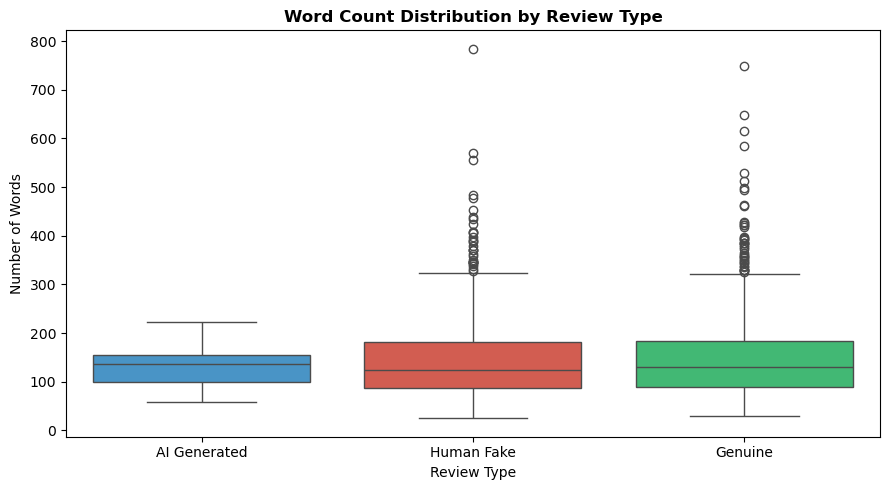

In [6]:
# number of words in each review
df['word_count'] = df['text'].str.split().str.len()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='label', y='word_count',
            order=CLASS_ORDER, palette=CLASS_COLORS, ax=ax)

ax.set_xticklabels(CLASS_LABELS)
ax.set_title('Word Count Distribution by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Words')

plt.tight_layout()
plt.show()

### 3.4 Average Word Count by Class

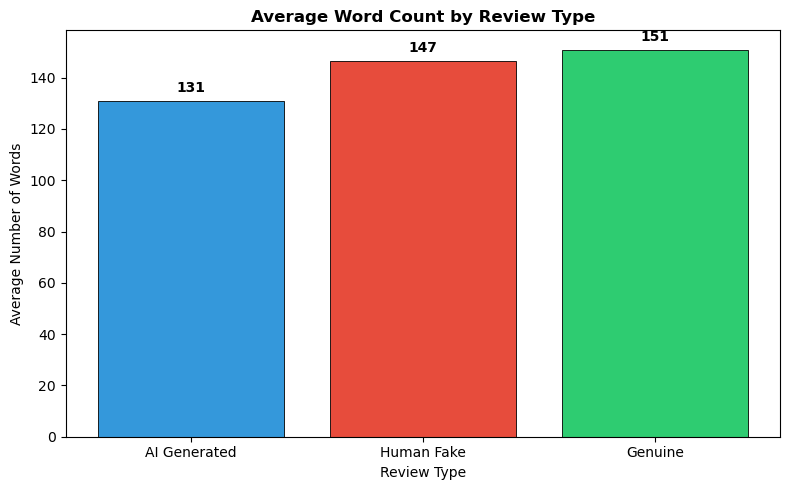

In [7]:
# average words per class
avg_words = df.groupby('label')['word_count'].mean().reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_LABELS, avg_words.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('Average Word Count by Review Type', fontweight='bold')
ax.set_ylabel('Average Number of Words')
ax.set_xlabel('Review Type')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.0f}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.5 Polarity Distribution by Class

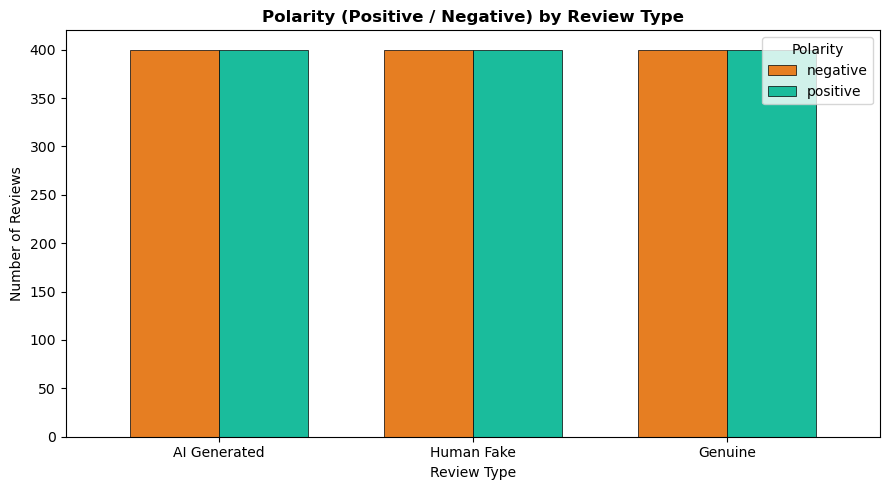

In [8]:
# positive/negative count for each class
polarity_ct = pd.crosstab(df['label'], df['polarity']).reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(9, 5))
polarity_ct.plot(kind='bar', ax=ax,
                 color=['#e67e22', '#1abc9c'],
                 edgecolor='black', linewidth=0.5, width=0.7)

ax.set_xticklabels(CLASS_LABELS, rotation=0)
ax.set_title('Polarity (Positive / Negative) by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Reviews')
ax.legend(title='Polarity')

plt.tight_layout()
plt.show()

### 3.6 Source Distribution

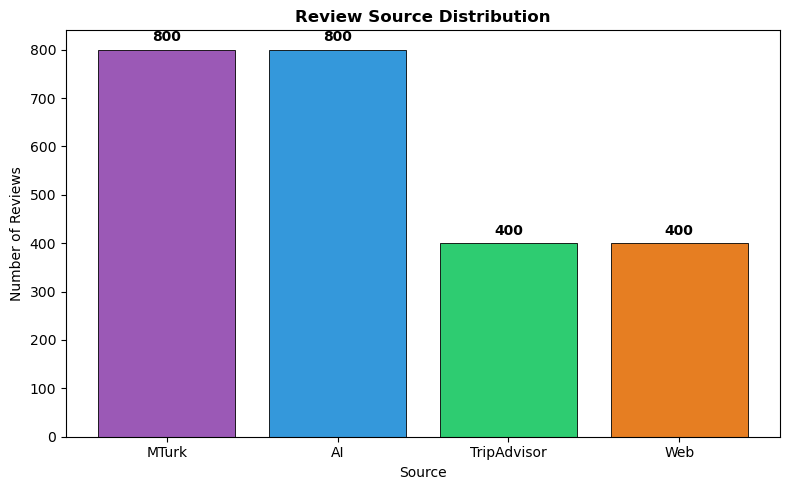

In [9]:
# reviews per source
source_counts = df['source'].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(source_counts.index, source_counts.values,
              color=['#9b59b6', '#3498db', '#2ecc71', '#e67e22'],
              edgecolor='black', linewidth=0.6)

ax.set_title('Review Source Distribution', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Source')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.7 Length Summary Statistics

In [10]:
# mean, median and std of length per class
length_summary = (df.groupby('label')[['char_length', 'word_count']]
                    .agg(['mean', 'median', 'std']).round(1)
                    .reindex(CLASS_ORDER))
length_summary.index = CLASS_LABELS
print('Review Length Summary Statistics of Hotel Datasets')
display(length_summary)

Review Length Summary Statistics of Hotel Datasets


char_length               word_count             
                    mean median    std       mean median   std
AI Generated       691.3  715.0  185.3      131.0  135.5  36.0
Human Fake         791.8  680.5  449.0      146.6  125.0  84.8
Genuine            821.0  710.5  484.7      150.9  130.0  89.8

## 4. Load & Explore Amazon Genuine Sample

In [11]:
# read the amazon data
amazon = pd.read_csv('amazon_genuine_sample.csv')
print(f'Amazon sample shape: {amazon.shape}')
print(f'Columns: {amazon.columns.tolist()}')
amazon.head(3)

Amazon sample shape: (2000, 9)
Columns: ['reviewerId', 'reviewId', 'verifiedPurchase', 'reviewDate', 'reviewText', 'starRating', 'helpfulVote', 'reviewTitle', 'prodId']


,reviewerId,reviewId,verifiedPurchase,reviewDate,reviewText,starRating,helpfulVote,reviewTitle,prodId
0,AHIQOEUXTHAPEDJMGNZODZIG6VCA,R3KVI1Q277SYQK,True,"January 30, 2017",Very nice product. Works great.,4.0,0,Four Stars,B01I8ETGLS
1,AF42IU6JXT3FBGPO5ERZAW5ZRZ7A,R2LPFLRNO8C2MC,False,"June 2, 2015",its ok but my teeth were very sensitive after it,3.0,0,Three Stars,B006QOE5N2
2,AFNSC7DG4GCGHYVWMTWBS4UG7ZFA,R1JARAESLTJ9SR,True,"April 29, 2017","I'm glad I purchased this corkscrew, I was tir...",5.0,0,High quality. Well worth it.,B00WOP3WPY


In [12]:
# Basic cleaning of Amazon data
amazon = amazon.dropna(subset=['reviewText']).copy()
amazon['reviewText'] = amazon['reviewText'].astype(str)

# Keep only reasonable length reviews
amazon = amazon[amazon['reviewText'].str.len() > 20].copy()

amazon['char_length'] = amazon['reviewText'].str.len()
amazon['word_count']  = amazon['reviewText'].str.split().str.len()
amazon['domain'] = 'Amazon Genuine'

print(f'Cleaned Amazon genuine reviews: {len(amazon)}')
print('\nStar rating distribution:')
print(amazon['starRating'].value_counts(dropna=False).head(10))

Cleaned Amazon genuine reviews: 1795

Star rating distribution:
starRating
5.0    1215
4.0     257
1.0     125
3.0     122
2.0      69
The       7
Name: count, dtype: int64


In [13]:
# Remove invalid starRating values
amazon = amazon[pd.to_numeric(amazon['starRating'], errors='coerce').notna()].copy()
amazon['starRating'] = amazon['starRating'].astype(float)

print(f'Cleaned Amazon genuine reviews: {len(amazon)}')
print('\nStar rating distribution:')
print(amazon['starRating'].value_counts(dropna=False).head(10))

Cleaned Amazon genuine reviews: 1788

Star rating distribution:
starRating
5.0    1215
4.0     257
1.0     125
3.0     122
2.0      69
Name: count, dtype: int64


### 4.1 Domain Comparison: Character Length (Hotel Genuine vs Amazon Genuine)

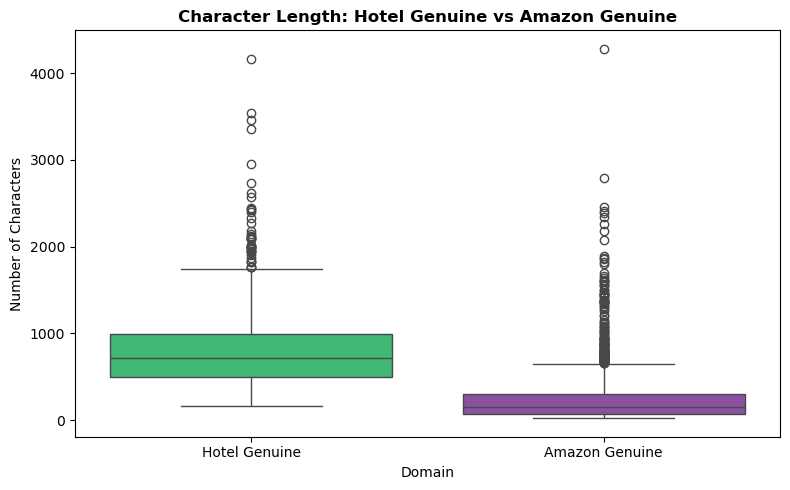

In [14]:
# only genuine hotel reviews, to compare with amazon
hotel_genuine = df[df['label'] == 'truthful'][['char_length', 'word_count']].copy()
hotel_genuine['domain'] = 'Hotel Genuine'

compare_len = pd.concat([
    hotel_genuine[['char_length', 'domain']],
    amazon[['char_length', 'domain']]
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=compare_len, x='domain', y='char_length',
            palette=DOMAIN_COLORS, ax=ax)

ax.set_title('Character Length: Hotel Genuine vs Amazon Genuine', fontweight='bold')
ax.set_xlabel('Domain')
ax.set_ylabel('Number of Characters')

plt.tight_layout()
plt.show()

### 4.2 Domain Comparison: Word Count

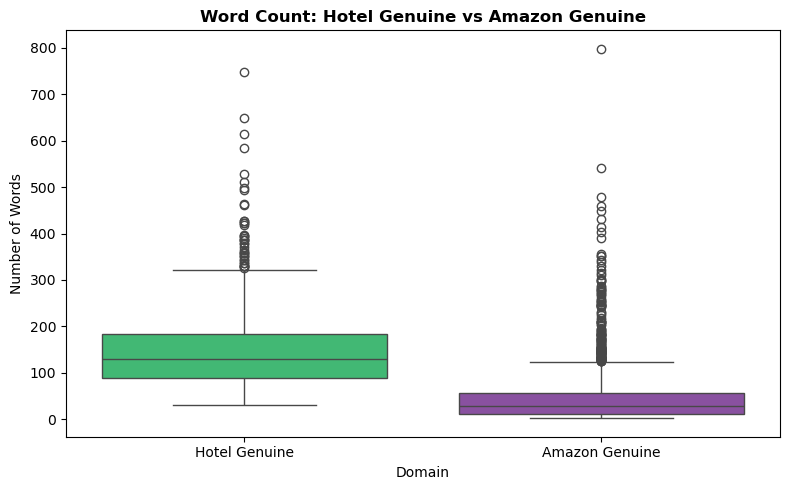

In [15]:
# same comparison using word count
compare_words = pd.concat([
    hotel_genuine[['word_count', 'domain']],
    amazon[['word_count', 'domain']]
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=compare_words, x='domain', y='word_count',
            palette=DOMAIN_COLORS, ax=ax)

ax.set_title('Word Count: Hotel Genuine vs Amazon Genuine', fontweight='bold')
ax.set_xlabel('Domain')
ax.set_ylabel('Number of Words')

plt.tight_layout()
plt.show()

### 4.3 Average Length Comparison

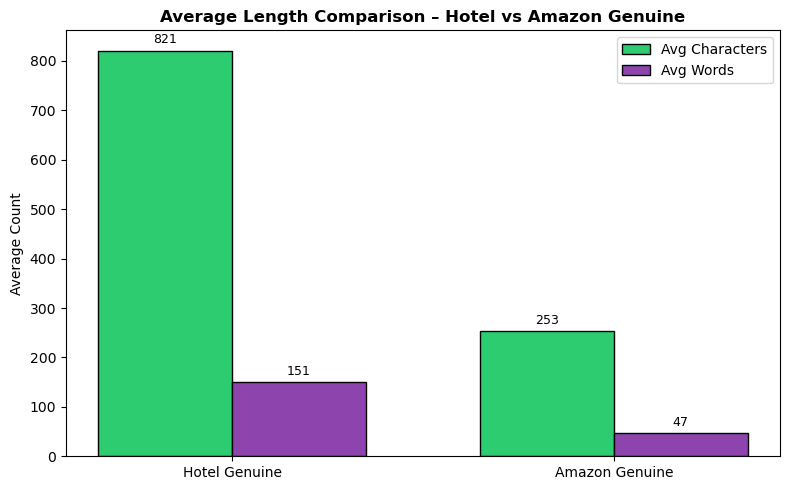

In [16]:
# average length of hotel vs amazon
avg_compare = pd.DataFrame({
    'Domain': ['Hotel Genuine', 'Amazon Genuine'],
    'Avg Characters': [
        hotel_genuine['char_length'].mean(),
        amazon['char_length'].mean()
    ],
    'Avg Words': [
        hotel_genuine['word_count'].mean(),
        amazon['word_count'].mean()
    ]
})

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(avg_compare))
width = 0.35

bars1 = ax.bar(x - width/2, avg_compare['Avg Characters'], width,
               label='Avg Characters', color='#2ecc71', edgecolor='black')
bars2 = ax.bar(x + width/2, avg_compare['Avg Words'], width,
               label='Avg Words', color='#8e44ad', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(avg_compare['Domain'])
ax.set_title('Average Length Comparison – Hotel vs Amazon Genuine', fontweight='bold')
ax.set_ylabel('Average Count')
ax.legend()

for bar in list(bars1) + list(bars2):
    height = bar.get_height()
    ax.annotate(f'{height:.0f}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Text Preprocessing

1. Lowercasing
2. Punctuation & number removal
3. Stop-word removal
4. Lemmatization

In [17]:
# stopwords and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# clean the text: lowercase, remove symbols and stopwords, lemmatize
def preprocess_text(text):
    """Clean and normalise review text."""
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = word_tokenize(text)
    tokens = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in stop_words and len(tok) > 2
    ]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess_text)
print('Preprocessed main dataset')

amazon['clean_text'] = amazon['reviewText'].apply(preprocess_text)
print('Preprocessed Amazon sample')

Preprocessed main dataset
Preprocessed Amazon sample


## 6. Feature Extraction  
#### TF-IDF & Train/Test Split

In [18]:
# turn labels into numbers
le = LabelEncoder()
le.fit(CLASS_ORDER)
df['label_id'] = le.transform(df['label'])

print('Label mapping:')
for i, name in enumerate(le.classes_):
    print(f'  {i}: {name} ({CLASS_LABELS[i]})')

X = df['clean_text']
y = df['label_id']

# 80/20 split, same share of each class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'\nTrain size: {len(X_train)} | Test size: {len(X_test)}')
print('Train class distribution:')
print(pd.Series(y_train).value_counts().sort_index())

Label mapping:
  0: AI generated (AI Generated)
  1: deceptive (Human Fake)
  2: truthful (Genuine)

Train size: 1920 | Test size: 480
Train class distribution:
label_id
0    640
1    640
2    640
Name: count, dtype: int64


In [19]:
# tf-idf: fit on train only, then apply on test
tfidf = TfidfVectorizer(
    max_features=6000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f'TF-IDF matrix shape: {X_train_tfidf.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_)}')

TF-IDF matrix shape: (1920, 6000)
Vocabulary size: 6000


## 7. Model Training & Evaluation


In [20]:
# train one model and return its scores
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision (macro)': precision_score(y_te, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_te, y_pred, average='macro'),
        'F1-score (macro)': f1_score(y_te, y_pred, average='macro')
    }
    return metrics, y_pred, model

In [21]:
# 4 models with default settings
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Naive Bayes': MultinomialNB(),
    'XGBoost': xgb.XGBClassifier(random_state=42)
}

# train each model and store the results
results = []
trained_models = {}
predictions = {}

print('Training models on Hotel dataset:\n')
for name, model in models.items():
    metrics, y_pred, fitted = evaluate_model(
        model, X_train_tfidf, y_train, X_test_tfidf, y_test, name
    )
    results.append(metrics)
    trained_models[name] = fitted
    predictions[name] = y_pred

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

Training models on Hotel dataset:



,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9334,0.9333,0.9330
Random Forest,0.8375,0.8345,0.8375,0.8339
Naive Bayes,0.9250,0.9246,0.9250,0.9248
XGBoost,0.8854,0.8845,0.8854,0.8848


### 7.1 Model Performance Comparison

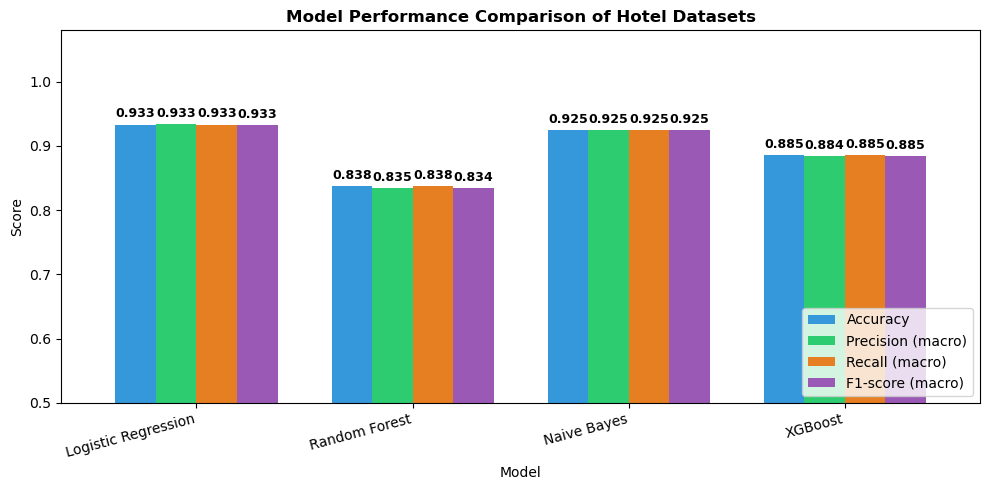

In [22]:
# compare all models in one chart
fig, ax = plt.subplots(figsize=(10, 5))

results_df.plot(
    kind='bar',
    ax=ax,
    width=0.75,
    color=['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
)

ax.set_title('Model Performance Comparison of Hotel Datasets', fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.08)

ax.legend(loc='lower right')

# Add labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',
        padding=3,
        fontsize=9,
        fontweight='bold'
    )

ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.show()

## 7.2 XGBoost Hyperparameter Tuning

In [23]:
# try different xgboost settings (train data only)
xgb_base = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=len(CLASS_ORDER),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.2]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_distributions,
    n_iter=12,
    scoring='f1_macro',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train_tfidf, y_train)

print('Best cross-validation macro F1:', round(xgb_search.best_score_, 4))
print('\nBest hyperparameters:')
for parameter, value in xgb_search.best_params_.items():
    print(f'{parameter}: {value}')

# keep the best model
xgb_model = xgb_search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best cross-validation macro F1: 0.8548

Best hyperparameters:
subsample: 1.0
n_estimators: 300
min_child_weight: 3
max_depth: 3
learning_rate: 0.1
gamma: 0.1
colsample_bytree: 1.0


### 7.3 Test-Set Evaluation of Tuned XGBoost

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Baseline XGBoost,0.8854,0.8845,0.8854,0.8848
Tuned XGBoost,0.8750,0.8747,0.8750,0.8747


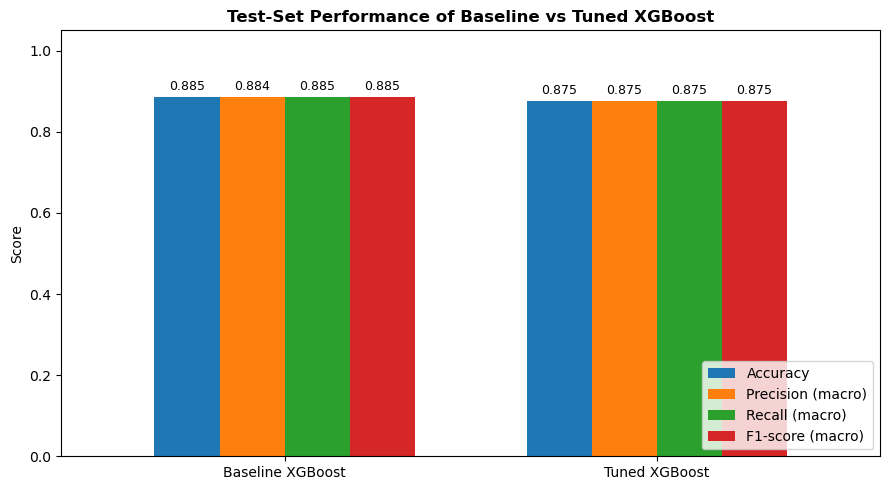

In [24]:
# test score of tuned xgboost vs normal xgboost
y_pred_xgb = xgb_model.predict(X_test_tfidf)

tuned_xgb_metrics = {
    'Model': 'Tuned XGBoost',
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision (macro)': precision_score(y_test, y_pred_xgb, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_xgb, average='macro'),
    'F1-score (macro)': f1_score(y_test, y_pred_xgb, average='macro')
}

xgb_comparison = pd.DataFrame([
    results_df.loc['XGBoost'].to_dict(),
    {key: value for key, value in tuned_xgb_metrics.items() if key != 'Model'}
], index=['Baseline XGBoost', 'Tuned XGBoost']).round(4)

display(xgb_comparison)

fig, ax = plt.subplots(figsize=(9, 5))
xgb_comparison.plot(kind='bar', ax=ax, width=0.7)
ax.set_title('Test-Set Performance of Baseline vs Tuned XGBoost', fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### 7.4 Confusion Matrix of Tuned XGBoost

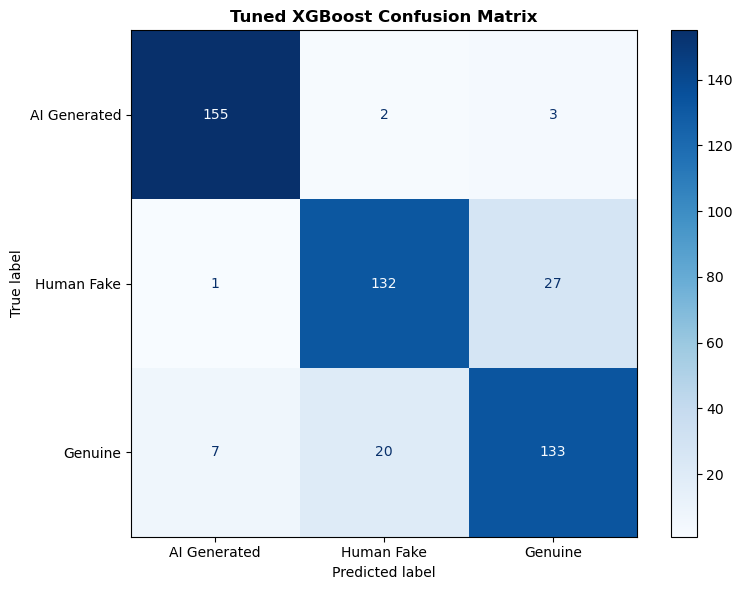

In [25]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
disp.plot(ax=ax, cmap='Blues', colorbar=True)
ax.set_title('Tuned XGBoost Confusion Matrix', fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Generalisation Check


### 8.1. Generalisation Check on Tuned XGBoost

In [26]:
# Sample Amazon reviews for the check
amazon_sample = amazon.sample(n=min(400, len(amazon)), random_state=42)

X_amazon_tfidf = tfidf.transform(amazon_sample['clean_text'])
# predict the class of amazon reviews
amazon_pred = xgb_model.predict(X_amazon_tfidf)
amazon_pred_labels = le.inverse_transform(amazon_pred)

pred_counts = pd.Series(amazon_pred_labels).value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)

print('Predicted class distribution on Amazon Genuine sample using Tuned XGBoost:')
print(pred_counts)
print(f'\nPercentage predicted as Genuine using Tuned XGBoost: {100 * pred_counts["truthful"] / len(amazon_sample):.1f}%')

Predicted class distribution on Amazon Genuine sample using Tuned XGBoost:
AI generated      0
deceptive        32
truthful        368
Name: count, dtype: int32

Percentage predicted as Genuine using Tuned XGBoost: 92.0%


### 8.2. Generalisation Check on Logistic Regression

In [27]:
# Sample Amazon reviews for the check
amazon_sample = amazon.sample(n=min(400, len(amazon)), random_state=42)

X_amazon_tfidf = tfidf.transform(amazon_sample['clean_text'])

lr = LogisticRegression(random_state=42)
lr_model = lr.fit(X_train_tfidf, y_train)
# predict the class of amazon reviews
amazon_pred = lr_model.predict(X_amazon_tfidf)
amazon_pred_labels = le.inverse_transform(amazon_pred)

pred_counts_lr = pd.Series(amazon_pred_labels).value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)

print('Predicted class distribution on Amazon Genuine sample using Logistic Regression:')
print(pred_counts_lr)
print(f'\nPercentage predicted as Genuine using Logistic Regression: {100 * pred_counts_lr["truthful"] / len(amazon_sample):.1f}%')

Predicted class distribution on Amazon Genuine sample using Logistic Regression:
AI generated     13
deceptive        57
truthful        330
Name: count, dtype: int32

Percentage predicted as Genuine using Logistic Regression: 82.5%


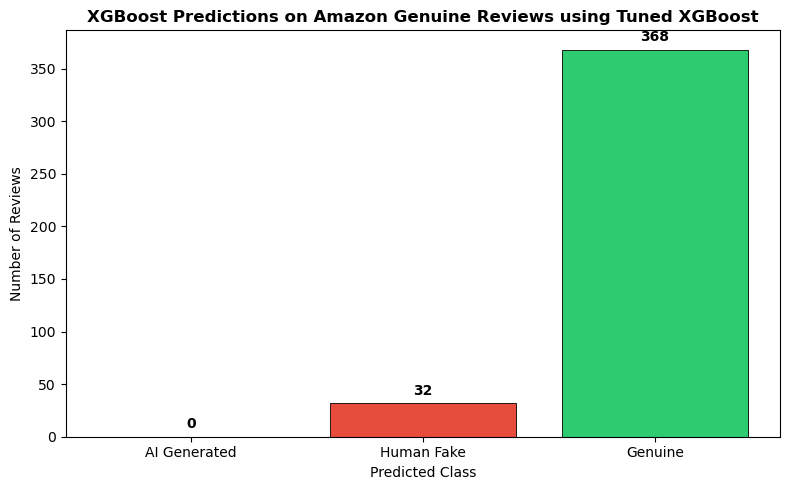

In [28]:
# plot what the model predicted for amazon reviews
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_LABELS, pred_counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('XGBoost Predictions on Amazon Genuine Reviews using Tuned XGBoost', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Predicted Class')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Explainability with SHAP

In [29]:
# explain predictions using shap
explainer = shap.TreeExplainer(xgb_model)

print('Computing SHAP values on a sample of the test set:')
sample_size = min(200, X_test_tfidf.shape[0])
X_sample = X_test_tfidf[:sample_size]

shap_values = explainer.shap_values(X_sample)
print("SHAP values ready.")

Computing SHAP values on a sample of the test set:
SHAP values ready.


In [30]:
feature_names = tfidf.get_feature_names_out()

# Extract SHAP values for each class
if isinstance(shap_values, list):
    shap_ai_generated = shap_values[0]
    shap_human_fake = shap_values[1]
    shap_genuine = shap_values[2]
else:
    shap_ai_generated = shap_values[:, :, 0]
    shap_human_fake = shap_values[:, :, 1]
    shap_genuine = shap_values[:, :, 2]

# Convert sparse matrix to dense
X_sample_dense = X_sample.toarray()

### 9.1 Top Features for Genuine Class

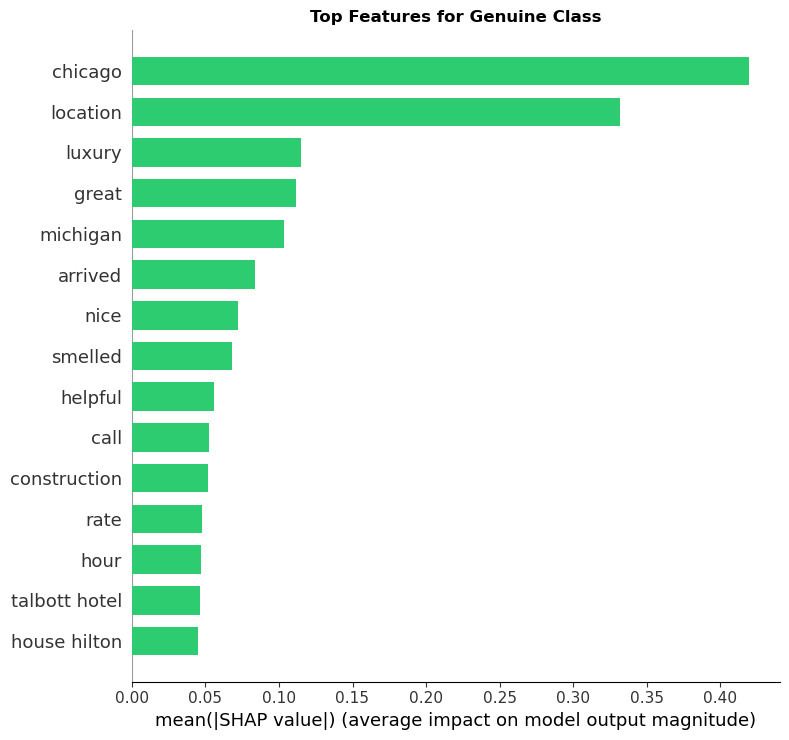

In [31]:
# top 15 words for genuine class
shap.summary_plot(
    shap_genuine, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#2ecc71'
)

plt.title('Top Features for Genuine Class', fontweight='bold')
plt.tight_layout()
plt.show()

### 9.2 Top Features for Human Fake Class

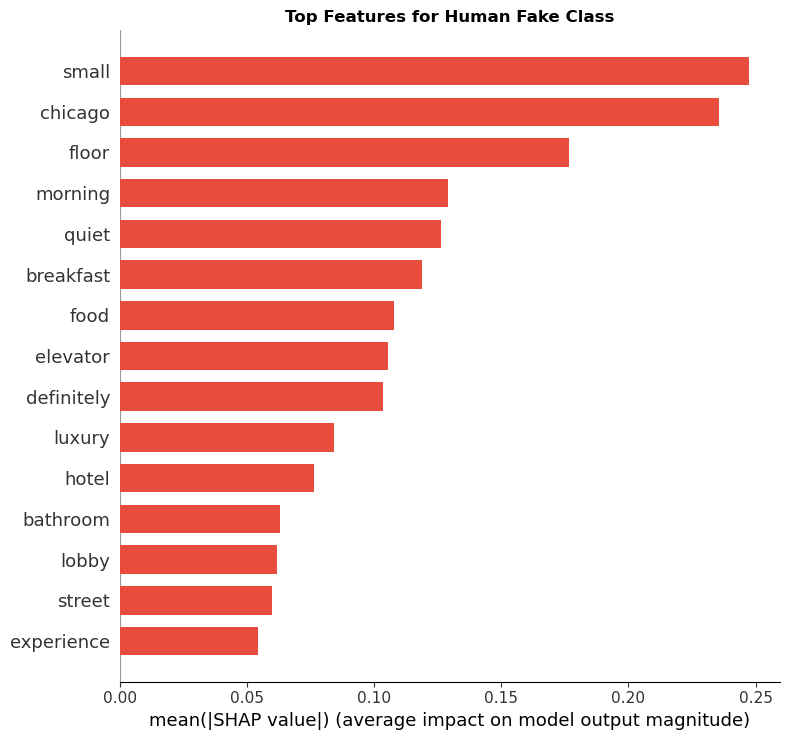

In [32]:
# top 15 words for human fake class
shap.summary_plot(
    shap_human_fake, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#e74c3c'
)

plt.title('Top Features for Human Fake Class', fontweight='bold')
plt.tight_layout()
plt.show()

### 9.3 Top Features for AI Generated Class

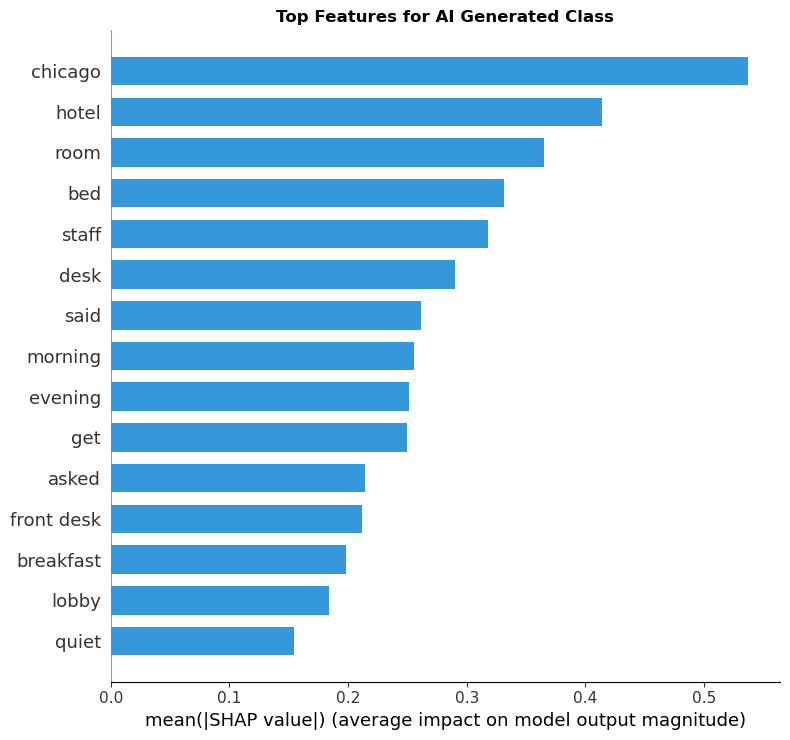

In [33]:
# top 15 words for AI generated class
shap.summary_plot(
    shap_ai_generated, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#3498db'
)

plt.title('Top Features for AI Generated Class', fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Final Conclusion

- The tuned XGBoost reached 87.50% accuracy and 0.8747 macro F1 (420 of 480 test reviews correct). The default XGBoost scored 88.54%, so tuning did not raise the hotel test score.
- AI Generated reviews were separated best (F1 0.960, 155 of 160 correct).
- Human Fake (F1 0.841) and Genuine (F1 0.824) were harder, and 47 of the 60 errors are between these two.
- XGBoost was not the highest scoring model: Logistic Regression (93.33%) and Naive Bayes (92.50%) scored higher even with default settings.
- Logistic Regression performed best on the hotel test set, but Tuned XGBoost gave better accuracy in generalisation. On the same 400 Amazon genuine reviews it predicted 92.0% as Genuine, against 82.5% for Logistic Regression, and made no AI Generated predictions (Logistic Regression made 13).
- Tuned XGBoost transfers well to another domain despite much shorter reviews (about 47 words against 151 for hotels).
- Genuine: place names and specific stay details (chicago, location, michigan, arrived, smelled, construction).
- Human Fake: room and hotel feature words with emphatic words (small, floor, quiet, breakfast, elevator, definitely, luxury).
- AI Generated: generic hotel-service and narration words (hotel, room, bed, staff, desk, said, asked, front desk).
- The per-class SHAP bar plots give readable word lists that match how each type of review is written.
- The plots show the average strength of words, not direction, and some top words (chicago, michigan) are specific to this hotel corpus.